# 4 · Modeling — Binôme B: convolutional autoencoders

**CRISP-DM phase 4 (Modeling).** Team: Khaled & Adrian (FR, Binôme B). Previous: [`../3_Data_Preparation.ipynb`](../3_Data_Preparation.ipynb) · Next: [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb)

**Idea** (DL notes, Cap. 9.11): train an autoencoder **only on normal data**. It reconstructs normal road scenes well and unexpected objects badly, so the **reconstruction error** is the anomaly score; a threshold turns it into a mask.

| Part | Model | Role |
|---|---|---|
| 1 | **Pixel autoencoder** on 64x64 normal patches, four reconstruction losses (MSE, MAE, MAE + VGG19 perceptual, SSIM) | baseline → `models/B_pixel_ae/` |
| 2 | **Feature-space autoencoder** on frozen ImageNet VGG16 features, with control experiments | **final model** → `models/B_feature_ae/` |

**Protocol.** Every choice (architecture, loss, depth, smoothing, threshold, minimum blob) is made on the **validation split only**. This notebook never loads the test split: the single test evaluation of all models is in notebook 5, and the explanations (Grad-CAM++ for *where*, exact SHAP for *what*) are in notebook 6.

**Decisions inherited from notebooks 2 and 3**

| Data finding | What this notebook does |
|---|---|
| No image is anomaly-free, but thousands of 64x64 patches of the **train** images are (nb 2 §9, nb 3 §3) | Learn "normal" from anomaly-free regions of the train split (`normal_regions`) |
| Working resolution 352x640 (nb 2 §7) | The autoencoders are fully convolutional and run on whole images at test time |
| Almost no object in the top of the image; no perspective trend (nb 2 §6) | Augmentation: horizontal flip only |
| 9.85 % anomaly pixels, so accuracy is meaningless (nb 2 §10) | AuPRC is the main metric; AUROC and AUPRO next to their chance levels |
| Several obstacles per image, many of them small (nb 2 §10) | Object recall and false alarms, small objects reported apart |

## TL;DR — a copier that only ever copied normal roads

**The idea.** An autoencoder is like a student who has only ever practised copying normal road scenes, through a very narrow memory (the bottleneck). Ask it to copy a road with a cow on it and the cow comes out wrong. **The copying error is the alarm.** Nice property: it never needs an outlined obstacle to learn, only the obstacle-free parts of the training photos (5,325 tiles of 64×64).

**Part 1, copying pixels (baseline).** The pixel autoencoder copies colours and textures, so what it finds "unusual" is unusual *texture*: foliage, façades, sky gradients. A grey boulder on a grey road is copied fine, and missed. Validation AuPRC **0.157** (a blind guess scores 0.091), whatever the loss (MSE, MAE, MAE + VGG19, SSIM: 0.121–0.157).

**Part 2, copying meanings (final model).** The same idea, moved from pixels to the **features of a frozen VGG16** (one 512-number description per 16×16-px cell): the autoencoder now copies *what is there*, not *which colour*. Validation AuPRC **0.596**, almost four times the pixel version. A threshold of 0.595 and a minimum blob of 256 px, both chosen on validation, keep its warnings few: 29 blobs on validation, against 67 for the pixel version.

**The honest part.** A control with **no autoencoder at all**, only the size of the VGG feature vectors, scores about the same (0.627 on validation), and so does a Gaussian on the same features across 11 backbones. Most of the detection comes from ImageNet pre-training, not from the autoencoder. We report it rather than hide it: Binôme B's result must be read as "pretrained features + feature autoencoder".

**Weak spots.** Small obstacles (4 of 12 found on validation) and coarse 16-px outlines.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models import autoencoder as pixel_ae, feature_ae
from roadanomaly.normal_regions import MASK_MARGIN, normal_cells, normal_patches
from roadanomaly.protocol import FPR_LIMIT, IMG_SIZE, MIN_OBJECT_PX, SEED

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Hyper-parameters of this notebook (the protocol constants come from roadanomaly.protocol)
PATCH, STRIDE = 64, 32                  # normal training patches overlap by half
PIXEL_LEARNING_RATE = 1e-3
PIXEL_BATCH_SIZE = 64
PIXEL_MAX_EPOCHS = 150
PIXEL_PATIENCE = 8                      # early stopping on the validation loss
VGG_PERCEPTUAL_WEIGHT = 0.1             # weight of the VGG19 perceptual term (variant "mae_vgg19")

FEATURE_LAYERS = ["block3_conv3", "block4_conv3", "block5_conv3"]   # VGG16 depths: 1 cell = 4, 8, 16 px
ENSEMBLE_SEEDS = [SEED, SEED + 1, SEED + 2]
ROAD_PRIOR_SHARE = 0.01                 # ignore the top rows that hold < 1 % of the TRAIN anomaly pixels
MIN_BLOB_CANDIDATES = [MIN_OBJECT_PX, 64, 256]   # smallest predicted blob kept (px), chosen on validation
KEEP_MARGIN = 0.002                     # seed noise of the val AuPRC: smaller gains are not real

FIG_DIR = dp.FIG_DIR

# Reproducibility: same seed for Python, NumPy and TensorFlow, and deterministic GPU ops
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Load the shared split (train + validation)
Same split, resolution and mask convention as the other binômes. The masks of the train images are used **only** to find their normal regions; the masks of the validation images to choose settings.

In [3]:
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
print("x_train:", x_train.shape, "| x_val:", x_val.shape)
print(f"AuPRC chance level on validation = prevalence = {gt_val.mean():.4f}")

x_train: (42, 352, 640, 3) | x_val: (9, 352, 640, 3)
AuPRC chance level on validation = prevalence = 0.0907


# Part 1 — Baseline: pixel autoencoder

## 2. Normal training patches
The autoencoder must see **normal** content only. Every image is cut into overlapping 64x64 patches, and only the patches with **no anomaly pixel** are kept, after dilating each obstacle by `MASK_MARGIN` px (annotation borders are loose). The validation images go through the same steps; their normal patches give the validation loss for early stopping (DL notes, Cap. 5.4: never the test set).

train: kept 5325 normal patches of 7980 | val: kept 1128 of 1710


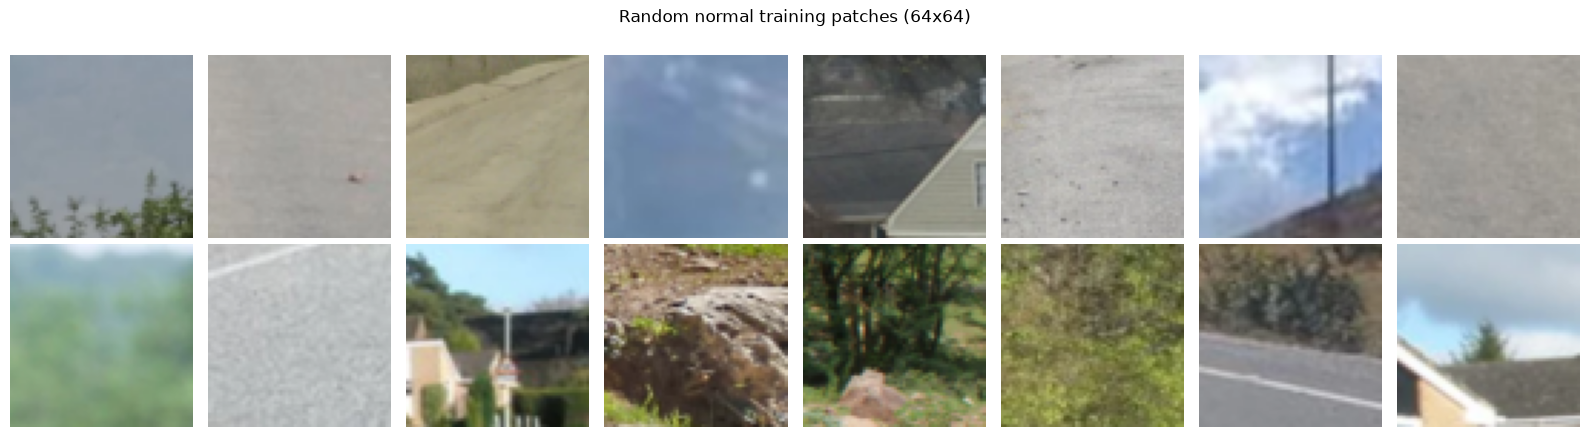

In [4]:
p_train, n_train = normal_patches(x_train, y_train, PATCH, STRIDE, MASK_MARGIN)
p_val, n_val = normal_patches(x_val, y_val, PATCH, STRIDE, MASK_MARGIN)
print(f"train: kept {len(p_train)} normal patches of {n_train} | val: kept {len(p_val)} of {n_val}")

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5), tight_layout=True)
for a, i in zip(ax.flat, np.random.default_rng(SEED).choice(len(p_train), 16, replace=False)):
    a.imshow(p_train[i]); a.axis("off")
plt.suptitle("Random normal training patches (64x64)")
plt.show()

In [5]:
# tf.data pipelines: shuffled + horizontally flipped for training, plain for validation
def augment_patch(patch):
    """Random horizontal flip only (scenes are never upside down). Returns (input, target)."""
    patch = tf.image.random_flip_left_right(patch)
    return patch, patch

train_patches = (tf.data.Dataset.from_tensor_slices(p_train).shuffle(len(p_train), seed=SEED)
                 .map(augment_patch, num_parallel_calls=tf.data.AUTOTUNE)
                 .batch(PIXEL_BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_patches = tf.data.Dataset.from_tensor_slices((p_val, p_val)).batch(PIXEL_BATCH_SIZE)

I0000 00:00:1793563122.195118 2513391 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## 3. Model: convolutional autoencoder (`roadanomaly.models.autoencoder`)
- **Encoder:** four stride-2 convolutions with ReLU halve the size four times (64 → 4).
- **Bottleneck:** a **linear** 4x4x2 code = 32 values for a 12,288-value patch (384x compression). The AE is strongly undercomplete, so it can only reproduce the *typical* appearance of a road scene.
- **Decoder:** mirrored `Conv2DTranspose` layers and a **sigmoid** output (pixels in [0, 1]).
- **No skip connections:** the information would bypass the bottleneck (that would be a U-Net, Cap. 10.3).
- **Fully convolutional:** trained on 64x64 patches, it reconstructs a whole 352x640 image (both sides divisible by 16).

**Why such a narrow bottleneck** (earlier model selection, validation only, sigma = 8; full record in `archive/B_feature_ae_and_backbone_study_adrian.ipynb`, section 3.1). A first version with 3 levels and 16 code channels (12x) reconstructed the obstacles **as well as the road** (Cap. 9.6: an AE that is too powerful "learns to reconstruct almost anything"). Narrowing the code raised the validation AuPRC from 0.096 (3 levels, 16 channels) to 0.151 (4 levels, 2 channels). A ReLU code collapsed on one of three seeds (a "dead" unit deletes half of a 2-channel code), so the code is linear.

In [6]:
pixel_ae.build_autoencoder().summary()

Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (Conv2D)              │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_2 (Conv2D)              │ (None, None, None, 64) │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_3 (Conv2D)              │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_4 (Conv2D)              │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, None, None, 2)  │         4,610 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Conv2DTranspose)     │ (None, None, None,     │         4,864 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_2 (Conv2DTranspose)     │ (None, None, None,     │       295,040 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_3 (Conv2DTranspose)     │ (None, None, None, 64) │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_4 (Conv2DTranspose)     │ (None, None, None, 32) │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Conv2D)         │ (None, None, None, 3)  │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 786,053 (3.00 MB)

 Trainable params: 786,053 (3.00 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Reconstruction losses (Khaled's comparison)
Same architecture, patches, split and seed; only the loss changes:
- **MSE**: the classic choice; the anomaly score is the same quantity per pixel.
- **MAE**: less sensitive to a few very bad pixels.
- **MAE + VGG19 perceptual loss**: adds the distance between the frozen ImageNet VGG19 features of the patch and of its reconstruction (weight 0.1), so the AE is pushed to keep textures and structures, not only colours.
- **SSIM**: structural similarity (luminance, contrast, structure) instead of a pixel difference.

The anomaly score stays the per-pixel squared RGB error for all four, so the comparison is about what the loss teaches the model, not about a different score.

In [7]:
def fit_variant(loss_name, perceptual=False):
    """Train one pixel AE at a fixed seed; returns (model, history)."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = pixel_ae.build_autoencoder()
    if perceptual:
        training_model = pixel_ae.PerceptualAutoencoder(model, pixel_ae.build_vgg19_feature_model(PATCH),
                                                        VGG_PERCEPTUAL_WEIGHT)
        training_model.compile(optimizer=keras.optimizers.Adam(PIXEL_LEARNING_RATE))
    else:
        training_model = model
        pixel_ae.compile_reconstruction_loss(model, loss_name, PIXEL_LEARNING_RATE)
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PIXEL_PATIENCE,
                                                   restore_best_weights=True)
    history = training_model.fit(train_patches, validation_data=val_patches, epochs=PIXEL_MAX_EPOCHS,
                                 callbacks=[early_stopping], verbose=0)
    return model, history.history

variants = {"mse": fit_variant("mse"), "mae": fit_variant("mae"),
            "mae_vgg19": fit_variant("mae", perceptual=True), "ssim": fit_variant("ssim")}
for name, (_, history) in variants.items():
    print(f"{name:10s} epochs {len(history['loss']):3d} | best epoch {int(np.argmin(history['val_loss'])) + 1:3d}")

mse        epochs  46 | best epoch  38
mae        epochs  45 | best epoch  37
mae_vgg19  epochs  33 | best epoch  25
ssim       epochs  26 | best epoch  18


## 5. From reconstruction to a score map, calibrated on validation
For each variant, the per-pixel squared error of the whole validation images goes through the shared post-processing (`roadanomaly.postprocessing`):
1. **Gaussian smoothing**, `sigma` chosen on validation by AuPRC: raw pixel errors are noisy, smoothing makes region-like scores;
2. **per-image z-score**: texture-rich images have a high error *everywhere*, so the score becomes "how unusual is this pixel compared with the rest of its own image" (assumes each image is mostly normal);
3. **threshold** maximising the per-image mean F1 on validation, then removal of blobs under `MIN_OBJECT_PX`.

The variant is chosen by validation **AuPRC** (main metric), with the per-image mean F1 as tie-breaker.

In [8]:
def calibrate(raw_maps, min_blob_candidates=(MIN_OBJECT_PX,)):
    """Sigma, threshold and minimum blob chosen on validation; returns settings, scores and the reports."""
    sigma, sigma_table = pp.select_sigma(gt_val, raw_maps)
    scores = pp.anomaly_scores(raw_maps, sigma)
    threshold, min_blob, _, _ = pp.select_threshold(gt_val, scores, min_blob_candidates=min_blob_candidates)
    free = evaluation.threshold_free_scores(gt_val, scores)
    report = evaluation.mask_report(gt_val, pp.to_masks(scores, threshold, min_blob))
    return {"sigma": sigma, "sigma_table": sigma_table, "threshold": threshold, "min_blob": min_blob,
            "scores": scores, "free": free, "report": report}

pixel_results = {}
for name, (model, history) in variants.items():
    recon_val, err_val = pixel_ae.reconstruction_error_maps(model, x_val)
    pixel_results[name] = {**calibrate(err_val), "recon": recon_val, "error": err_val}

pixel_table = pd.DataFrame({name: {**evaluation.summary(r["free"], r["report"]), "sigma": r["sigma"],
                                   "threshold": round(r["threshold"], 3)}
                            for name, r in pixel_results.items()})
PIXEL_WINNER = max(pixel_results, key=lambda n: (round(pixel_results[n]["free"]["AuPRC"], 3),
                                                 pixel_results[n]["report"]["pixel"]["per_image_mean"]["f1"]))
print("Baseline variant chosen on validation:", PIXEL_WINNER)
pixel_table

Baseline variant chosen on validation: mae_vgg19


,mse,mae,mae_vgg19,ssim
AuPRC (main),0.147674,0.150231,0.157301,0.120592
AUROC,0.676523,0.677968,0.694229,0.6109
AUPRO@0.3,0.506097,0.506821,0.527589,0.427339
FPR95 (lower is better),0.715087,0.729804,0.702401,0.777759
F1 = Dice (per-image mean),0.234211,0.237688,0.248721,0.196891
IoU (per-image mean),0.137817,0.140088,0.147532,0.112933
precision (per-image mean),0.168736,0.173223,0.179773,0.151029
recall (per-image mean),0.568787,0.573336,0.595062,0.505239
F1 (aggregated),0.227647,0.232094,0.246503,0.189427
Boundary IoU (15 px band),0.094684,0.095792,0.099324,0.124129


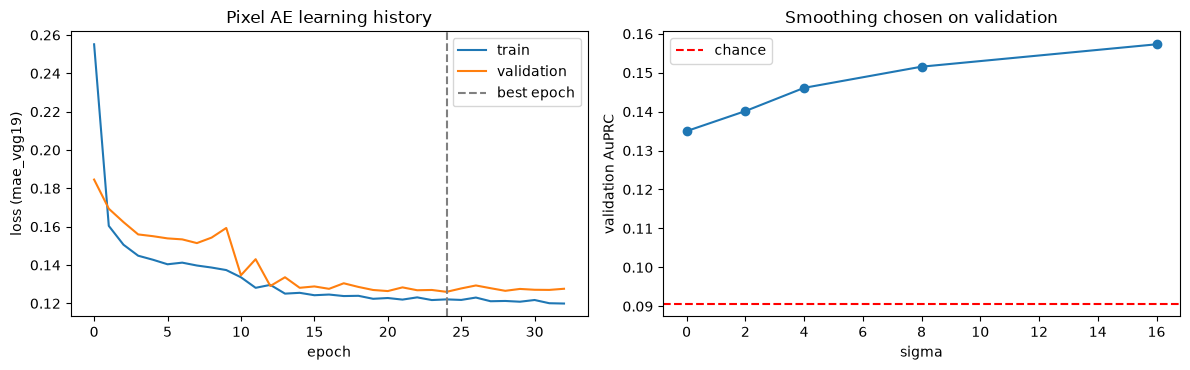

In [9]:
# Learning curves of the chosen variant and its sigma selection
history = variants[PIXEL_WINNER][1]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), tight_layout=True)
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].axvline(int(np.argmin(history["val_loss"])), color="gray", linestyle="--", label="best epoch")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel(f"loss ({PIXEL_WINNER})"); ax[0].legend()
ax[0].set_title("Pixel AE learning history")
table = pixel_results[PIXEL_WINNER]["sigma_table"]
ax[1].plot(list(table), list(table.values()), marker="o")
ax[1].axhline(gt_val.mean(), color="red", linestyle="--", label="chance")
ax[1].set_xlabel("sigma"); ax[1].set_ylabel("validation AuPRC"); ax[1].legend()
ax[1].set_title("Smoothing chosen on validation")
plt.savefig(FIG_DIR / "B_01_pixel_ae_training.png", dpi=80)
plt.show()

## 6. Where the false alarms come from (validation)
The 64x64 windows of the validation images with the most false-positive pixels, for the chosen variant. They show what a pixel autoencoder finds "unusual".

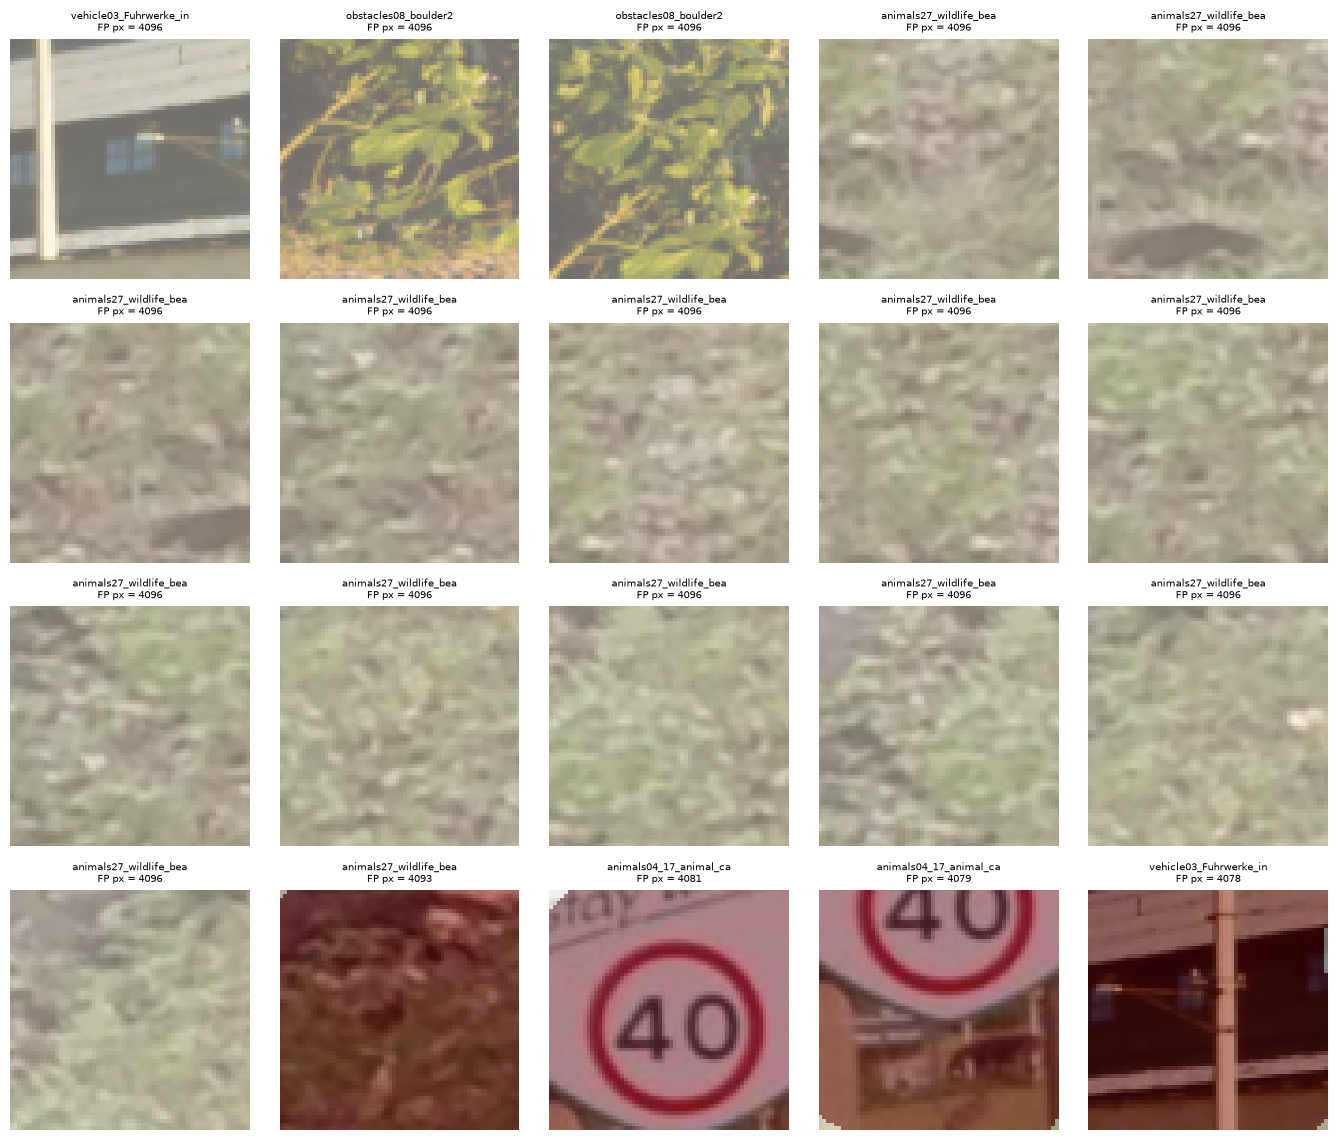

In [10]:
best = pixel_results[PIXEL_WINNER]
masks = pp.to_masks(best["scores"], best["threshold"], best["min_blob"]).astype(bool)
windows = []
for i, (truth, pred) in enumerate(zip(gt_val, masks)):
    for top in range(0, IMG_SIZE[0] - PATCH + 1, STRIDE):
        for left in range(0, IMG_SIZE[1] - PATCH + 1, STRIDE):
            fp = int((pred[top:top + PATCH, left:left + PATCH] & ~truth[top:top + PATCH, left:left + PATCH]).sum())
            if fp:
                windows.append((fp, i, top, left))
windows = sorted(windows, reverse=True)[:20]
fig, ax = plt.subplots(4, 5, figsize=(14, 11.5), tight_layout=True)
for a, (fp, i, top, left) in zip(ax.flat, windows):
    a.imshow(x_val[i, top:top + PATCH, left:left + PATCH])
    a.imshow((masks[i] & ~gt_val[i])[top:top + PATCH, left:left + PATCH], cmap="Reds", alpha=0.45)
    a.set_title(f"{val_frames[i][:22]}\nFP px = {fp}", fontsize=7)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "B_02_pixel_ae_false_positives.png", dpi=70)
plt.show()

**Reading the baseline.** The pixel autoencoder flags *unusual colour and texture*, not *unexpected objects*: foliage, leaf litter, building facades, sky gradients and high-contrast stripes produce most false alarms, while obstacles with ordinary colours (grey boulders on a grey road, a brown boar on brown leaves) are reconstructed well and missed. Changing the loss changes how textures are reproduced but not this limit, which is what Part 2 addresses.

In [11]:
# Save the baseline in the shared format (models/B_pixel_ae/)
best = pixel_results[PIXEL_WINNER]
history = variants[PIXEL_WINNER][1]
save_artifact(dp.MODELS_DIR / "B_pixel_ae", variants[PIXEL_WINNER][0], {
    "name": "B_pixel_ae", "binome": "B", "title": f"Pixel autoencoder ({PIXEL_WINNER} loss), baseline",
    "model_type": "pixel_autoencoder",
    "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
    "postprocessing": {"sigma": best["sigma"], "per_image_z_score": True, "threshold": best["threshold"],
                       "min_blob_px": best["min_blob"]},
    "selection": {"split": "val", "variant_rule": "best AuPRC, then per-image mean F1",
                  "threshold_rule": "best per-image mean F1"},
    "validation": {**best["free"], **best["report"]["pixel"]["per_image_mean"]},
    "training": {"loss": PIXEL_WINNER, "seed": SEED, "patch": PATCH, "stride": STRIDE, "mask_margin": MASK_MARGIN,
                 "normal_patches_train": len(p_train), "learning_rate": PIXEL_LEARNING_RATE,
                 "batch_size": PIXEL_BATCH_SIZE, "epochs_ran": len(history["loss"]),
                 "best_epoch": int(np.argmin(history["val_loss"])) + 1},
})
print("saved models/B_pixel_ae")

saved models/B_pixel_ae


# Part 2 — Final model: feature-space autoencoder

The pixel autoencoder measures *unusual appearance*. Part 2 keeps the autoencoder idea but moves it to a better space: a network pretrained on ImageNet (VGG16, **frozen**, used only as a fixed measuring tool) turns each image region into a feature vector, and the autoencoder learns to reconstruct the feature vectors of **normal road scenes**. An obstacle is a region whose features it cannot reconstruct.

Rules of this part:
- every choice uses the **validation split only**; the train masks are used only for normal cells and the road prior;
- the list of candidates is **short on purpose**: with 9 validation images, trying many variants would fit the validation set itself;
- a component is kept only if it raises the validation AuPRC by more than the seed noise (`KEEP_MARGIN` = 0.002);
- every result of the feature AE is shown next to a **control without any autoencoder**, so its own contribution stays visible.

## 7. Control experiment: where would a gain come from?
The simplest use of VGG is a *perceptual error*: compare the VGG features of the image with those of the pixel autoencoder's reconstruction. Before trusting it, it is compared with a **control that uses no reconstruction at all**: the size (L2 norm) of the feature vector at each position. If both score the same, the gain comes from the pretrained network and not from an autoencoder.

In [12]:
recon_val = pixel_results[PIXEL_WINNER]["recon"]
sigma_v1 = pixel_results[PIXEL_WINNER]["sigma"]

def free_auprc_auroc(raw_maps, sigma):
    free = evaluation.threshold_free_scores(gt_val, pp.anomaly_scores(raw_maps, sigma))
    return {"AuPRC": free["AuPRC"], "AUROC": free["AUROC"]}

control_rows = [{"layer": "pixels", "score map": f"pixel AE ({PIXEL_WINNER}), squared error",
                 **free_auprc_auroc(pixel_results[PIXEL_WINNER]["error"], sigma_v1)}]
for layer in FEATURE_LAYERS:
    f_image = feature_ae.extract_features(x_val, layer=layer)
    f_recon = feature_ae.extract_features(recon_val, layer=layer)
    control_rows.append({"layer": layer, "score map": "pixel AE, perceptual error",
                         **free_auprc_auroc(((f_image - f_recon) ** 2).mean(axis=-1), sigma_v1)})
    control_rows.append({"layer": layer, "score map": "control: feature norm, no AE",
                         **free_auprc_auroc(np.linalg.norm(f_image, axis=-1), sigma_v1)})
pd.DataFrame(control_rows).round(3)

,layer,score map,AuPRC,AUROC
0,pixels,"pixel AE (mae_vgg19), squared error",0.157,0.694
1,block3_conv3,"pixel AE, perceptual error",0.227,0.788
2,block3_conv3,"control: feature norm, no AE",0.217,0.789
3,block4_conv3,"pixel AE, perceptual error",0.300,0.809
4,block4_conv3,"control: feature norm, no AE",0.278,0.780
5,block5_conv3,"pixel AE, perceptual error",0.592,0.924
6,block5_conv3,"control: feature norm, no AE",0.598,0.918


**Reading the control.** The perceptual error is far better than the pixel error, but the plain feature norm, without any reconstruction, scores about **the same** at every depth: the improvement comes from the ImageNet features (an obstacle simply activates VGG more strongly than asphalt), not from the pixel autoencoder. The autoencoder therefore has to work **in feature space** to contribute.

## 8. Features for the autoencoder
- **Normal cells.** A feature cell is normal if its image region holds no anomaly pixel after dilating each obstacle by `MASK_MARGIN` px (`normal_regions.normal_cells`). The training input is the whole feature map; anomaly cells get **weight 0 in the loss**.
- **Standardisation.** VGG channels have very different scales, so each channel is z-scored with the mean and standard deviation of the **train** normal cells.

In [13]:
def prepare_features(layer):
    """Standardised train / val features of one VGG16 layer, their normal cells and the train statistics."""
    f_train = feature_ae.extract_features(x_train, layer=layer)
    f_val = feature_ae.extract_features(x_val, layer=layer)
    ok_train, ok_val = normal_cells(y_train, f_train.shape[1:3]), normal_cells(y_val, f_val.shape[1:3])
    mean, std = feature_ae.feature_statistics(f_train, ok_train)
    return {"train": feature_ae.standardise(f_train, mean, std), "val": feature_ae.standardise(f_val, mean, std),
            "ok_train": ok_train, "ok_val": ok_val, "mean": mean, "std": std}

def train_on(data, seed):
    """One feature AE trained on the normal cells of `data` (roadanomaly.models.feature_ae)."""
    return feature_ae.train_feature_ae(data["train"], data["ok_train"], data["val"], data["ok_val"], seed)

feature_ae.build_feature_ae(512).summary()

Model: "feature_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Conv2D)                │ (None, None, None,     │     1,179,904 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ code (Conv2D)                   │ (None, None, None, 8)  │         2,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Conv2D)                │ (None, None, None,     │        18,688 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Conv2D)         │ (None, None, None,     │       131,584 │
│                                 │ 512)                   │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,332,232 (5.08 MB)

 Trainable params: 1,332,232 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

**Model** (`roadanomaly.models.feature_ae`): the same design rules as the pixel AE, adapted to features. No stride (a cell already summarises a region, so the AE compresses the channels of each cell with a 3x3 neighbourhood); a narrow **linear** code of 8 channels per cell; a **linear** output (standardised features are unbounded); **masked MSE**; early stopping on the validation normal cells.

## 9. Which VGG depth? (validation only)
One feature AE per depth (seed `SEED`). The depth with the best **feature-AE** AuPRC is kept; the "no AE" columns use the same standardised features without any reconstruction.

In [14]:
layer_rows = []
for layer in FEATURE_LAYERS:
    data = prepare_features(layer)
    model, history = train_on(data, SEED)
    layer_rows.append({"layer": layer, "cells": f"{data['val'].shape[1]}x{data['val'].shape[2]}",
                       "epochs": len(history.history["loss"]),
                       **{f"feature AE {k}": v for k, v in free_auprc_auroc(feature_ae.cell_error_maps(model, data["val"]), sigma_v1).items()},
                       **{f"no AE {k}": v for k, v in free_auprc_auroc(np.linalg.norm(data["val"], axis=-1), sigma_v1).items()}})
del data, model
layer_df = pd.DataFrame(layer_rows).round(3)
FEATURE_LAYER = layer_df.loc[layer_df["feature AE AuPRC"].idxmax(), "layer"]
print("Chosen depth (best feature-AE AuPRC on validation):", FEATURE_LAYER)
layer_df

Chosen depth (best feature-AE AuPRC on validation): block5_conv3


,layer,cells,epochs,feature AE AuPRC,feature AE AUROC,no AE AuPRC,no AE AUROC
0,block3_conv3,88x160,224,0.26,0.812,0.274,0.831
1,block4_conv3,44x80,212,0.43,0.877,0.418,0.869
2,block5_conv3,22x40,62,0.59,0.920,0.629,0.939


## 10. Smoothing, road prior and seed ensemble (ablation on validation)
- **Smoothing:** sigma is chosen again, because a feature map is coarser than a pixel map.
- **Road prior:** notebook 2 found almost no obstacle in the top of the image. `ROAD_TOP_ROW` is learned from the **train masks only** (rows above it hold < 1 % of the train anomaly pixels), and their scores are set to the lowest score of the image.
- **Seed ensemble:** the feature AE trained with 3 seeds, error maps averaged.

Each component is added in turn and **kept only if the validation AuPRC rises by more than `KEEP_MARGIN`**.

In [15]:
anomaly_per_row = y_train[..., 0].sum(axis=(0, 2))
ROAD_TOP_ROW = int(np.argmax(np.cumsum(anomaly_per_row) / anomaly_per_row.sum() >= ROAD_PRIOR_SHARE))
print(f"ROAD_TOP_ROW = {ROAD_TOP_ROW} of {IMG_SIZE[0]} rows")

def feature_scores(cell_maps_per_seed, sigma, use_ensemble, use_prior):
    """Average over seeds (optional) -> upsample + smoothing + per-image z-score -> road prior (optional)."""
    cells = np.mean(cell_maps_per_seed, axis=0) if use_ensemble else cell_maps_per_seed[0]
    scores = pp.anomaly_scores(cells, sigma)
    if use_prior:
        scores = scores.copy()
        scores[:, :ROAD_TOP_ROW] = scores.min(axis=(1, 2), keepdims=True)
    return scores

data = prepare_features(FEATURE_LAYER)
ensemble = [train_on(data, seed)[0] for seed in ENSEMBLE_SEEDS]
cells_val = [feature_ae.cell_error_maps(model, data["val"]) for model in ensemble]

SIGMA_FEATURE, _ = pp.select_sigma(gt_val, cells_val[0])
config = {"sigma": sigma_v1, "use_ensemble": False, "use_prior": False}
scores_val = feature_scores(cells_val, **config)
ablation = [{"step": f"baseline: pixel AE ({PIXEL_WINNER})", **pixel_results[PIXEL_WINNER]["free"], "kept": "-"},
            {"step": f"feature AE on {FEATURE_LAYER} (1 seed, sigma {sigma_v1})",
             **evaluation.threshold_free_scores(gt_val, scores_val), "kept": "-"}]
for name, change in [(f"+ smoothing chosen on val (sigma {SIGMA_FEATURE})", {"sigma": SIGMA_FEATURE}),
                     (f"+ road prior (rows < {ROAD_TOP_ROW})", {"use_prior": True}),
                     (f"+ {len(ENSEMBLE_SEEDS)}-seed ensemble", {"use_ensemble": True})]:
    trial = {**config, **change}
    trial_scores = feature_scores(cells_val, **trial)
    row = evaluation.threshold_free_scores(gt_val, trial_scores)
    kept = row["AuPRC"] > pp.auprc(gt_val, scores_val) + KEEP_MARGIN
    if kept:
        config, scores_val = trial, trial_scores
    ablation.append({"step": name, **row, "kept": "yes" if kept else "no"})

control_val = feature_scores([np.linalg.norm(data["val"], axis=-1)], config["sigma"], False, config["use_prior"])
ablation.append({"step": f"control: {FEATURE_LAYER} features, no AE (same post-processing)",
                 **evaluation.threshold_free_scores(gt_val, control_val), "kept": "-"})
ablation_df = pd.DataFrame(ablation).drop(columns=["AuPRC chance", "AUROC chance", "AUPRO chance"]).round(3)
print("Final configuration:", config)
ablation_df

ROAD_TOP_ROW = 42 of 352 rows


Final configuration: {'sigma': 8, 'use_ensemble': False, 'use_prior': False}


,step,AuPRC,AUROC,FPR95,AUPRO,kept
0,baseline: pixel AE (mae_vgg19),0.157,0.694,0.702,0.528,-
1,"feature AE on block5_conv3 (1 seed, sigma 16)",0.590,0.920,0.358,0.706,-
2,+ smoothing chosen on val (sigma 8),0.596,0.913,0.409,0.700,yes
3,+ road prior (rows < 42),0.580,0.891,0.744,0.701,no
4,+ 3-seed ensemble,0.596,0.913,0.409,0.703,no
5,"control: block5_conv3 features, no AE (same po...",0.627,0.935,0.255,0.718,-


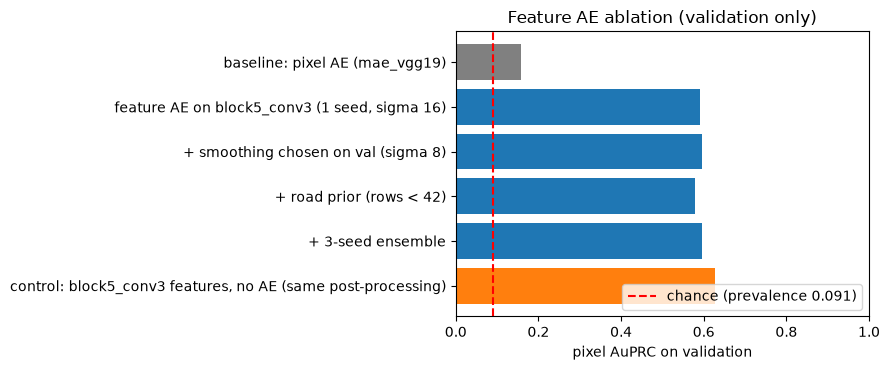

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8), tight_layout=True)
colours = ["grey"] + ["tab:blue"] * (len(ablation_df) - 2) + ["tab:orange"]
ax.barh(ablation_df["step"][::-1], ablation_df["AuPRC"][::-1], color=colours[::-1])
ax.axvline(gt_val.mean(), color="red", linestyle="--", label=f"chance (prevalence {gt_val.mean():.3f})")
ax.set_xlim(0, 1); ax.set_xlabel("pixel AuPRC on validation"); ax.set_title("Feature AE ablation (validation only)")
ax.legend(loc="lower right")
plt.savefig(FIG_DIR / "B_03_feature_ae_ablation.png", dpi=80)
plt.show()

## 11. Threshold and minimum blob size (validation only)
The threshold maximises the per-image mean F1 on validation, and the minimum size of a predicted blob is chosen at the same time (removing blobs smaller than a real obstacle may remove many false alarms). Only the **predictions** are filtered; the ground truth keeps the speckle limit of the protocol.

In [17]:
assert not config["use_ensemble"] and not config["use_prior"], \
    "the shared Predictor serves one model without road prior: extend inference.py before keeping these"
THRESHOLD, MIN_BLOB, best_f1, _ = pp.select_threshold(gt_val, scores_val, min_blob_candidates=MIN_BLOB_CANDIDATES)
print(f"Threshold {THRESHOLD:.4f} | minimum blob {MIN_BLOB} px | validation per-image mean F1 {best_f1:.4f}")

final_free = evaluation.threshold_free_scores(gt_val, scores_val)
final_report = evaluation.mask_report(gt_val, pp.to_masks(scores_val, THRESHOLD, MIN_BLOB))
pd.DataFrame({f"baseline: pixel AE ({PIXEL_WINNER})": evaluation.summary(pixel_results[PIXEL_WINNER]["free"],
                                                                          pixel_results[PIXEL_WINNER]["report"]),
              "final: feature AE": evaluation.summary(final_free, final_report)})

Threshold 0.5948 | minimum blob 256 px | validation per-image mean F1 0.5750


,baseline: pixel AE (mae_vgg19),final: feature AE
AuPRC (main),0.157301,0.59601
AUROC,0.694229,0.912895
AUPRO@0.3,0.527589,0.699699
FPR95 (lower is better),0.702401,0.409246
F1 = Dice (per-image mean),0.248721,0.575039
IoU (per-image mean),0.147532,0.421448
precision (per-image mean),0.179773,0.574594
recall (per-image mean),0.595062,0.710423
F1 (aggregated),0.246503,0.565917
Boundary IoU (15 px band),0.099324,0.224365


In [18]:
# Save the final model in the shared format (models/B_feature_ae/): AE weights + train feature statistics
model = ensemble[0]   # the seed-SEED model; the ensemble was not kept (section 10)
save_artifact(dp.MODELS_DIR / "B_feature_ae", model, {
    "name": "B_feature_ae", "binome": "B", "title": f"Feature-space autoencoder on frozen VGG16 {FEATURE_LAYER}",
    "model_type": "feature_autoencoder",
    "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
    "features": {"backbone": feature_ae.BACKBONE, "layer": FEATURE_LAYER, "weights": "imagenet (frozen)"},
    "postprocessing": {"sigma": config["sigma"], "per_image_z_score": True, "threshold": THRESHOLD,
                       "min_blob_px": MIN_BLOB},
    "selection": {"split": "val", "depth_rule": "best feature-AE AuPRC", "component_rule": f"AuPRC gain > {KEEP_MARGIN}",
                  "threshold_rule": "best per-image mean F1 (threshold and min blob together)"},
    "validation": {**final_free, **final_report["pixel"]["per_image_mean"]},
    "controls_validation_auprc": {"feature norm, no AE": pp.auprc(gt_val, control_val)},
    "training": {"seed": SEED, "hidden": feature_ae.HIDDEN, "code_channels": feature_ae.CODE_CHANNELS,
                 "learning_rate": feature_ae.LEARNING_RATE, "batch_size": feature_ae.BATCH_SIZE,
                 "mask_margin": MASK_MARGIN, "normal_cells_train": int(data["ok_train"].sum())},
}, feature_stats=(data["mean"], data["std"]))
print("saved models/B_feature_ae")

saved models/B_feature_ae


## 12. Is VGG16 the right backbone? (summary of the archived study)
Ten other ImageNet encoders from `keras.applications` were compared with the same feature AE, plus a PaDiM-style Gaussian control (Ledoit-Wolf covariance, Mahalanobis distance), on **validation only**. The full study, with its code and outputs, is kept in `archive/B_feature_ae_and_backbone_study_adrian.ipynb` (section 14); its result fixed the backbone used above.

| Rank | Backbone | AE AuPRC | AE AUPRO | Best control AuPRC | AE − control | ms / image (RTX 4060) |
|---|---|---|---|---|---|---|
| 1 | **VGG16** | **0.596** | 0.700 | 0.629 | −0.033 | 24.4 |
| 2 | VGG19 | 0.592 | 0.655 | 0.604 | −0.012 | 30.1 |
| 3 | Xception | 0.588 | **0.788** | 0.587 | +0.001 | 22.1 |
| 4 | ResNet50 | 0.541 | 0.730 | 0.523 | +0.018 | 26.3 |
| 5 | DenseNet121 | 0.527 | 0.748 | 0.513 | +0.014 | 32.9 |
| 6–11 | ResNet101, EfficientNetV2S, ConvNeXtTiny, EfficientNetB0, MobileNetV3Large, ResNet50V2 | 0.31–0.51 | | | | 15–44 |

VGG16, VGG19 and Xception are within noise of each other. Newer batch-normalised networks are worse here; a likely reason (a hypothesis) is that VGG has no batch normalisation, so the *size* of its activations still signals a salient object.

## 13. Findings of the modeling phase (validation)
- **Feature space is what matters.** Moving the autoencoder from pixels to frozen ImageNet features multiplies the validation AuPRC several times (sections 10–11). The worst baseline failures (grey boulder on a grey road, brown boar on leaves) are typical successes of the feature AE.
- **The autoencoder itself adds little.** At the chosen depth, the plain feature norm without any AE scores about as well as the feature AE (section 10, orange bar), and across 11 backbones the AE is about equal to a Gaussian on the same features (section 12). With 42 training images, most of the detection ability comes from ImageNet pre-training. This is reported as a finding, and the group comparison must read Binôme B as "pretrained features + feature AE".
- **Dropped on validation evidence:** the road prior (the bear and the Czech hedgehog of validation reach the top of the frame) and the 3-seed ensemble (no variance left to remove).
- **Known weaknesses:** small objects (a 16-px cell and a large minimum blob trade them for fewer false alarms), coarse boundaries, and ordinary objects that are not labelled as anomalies (bollards, pedestrians, a house).
- **External knowledge:** VGG16 / VGG19 weights come from ImageNet, the same kind of transfer learning as Binôme A's backbone; to be stated in the report and confirmed as allowed for Binôme B.

The test split has not been used here. Both B models are evaluated once, with A and C, in [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb); their paired explanations (Grad-CAM++ and exact SHAP) are in [`../6_XAI.ipynb`](../6_XAI.ipynb).